# MSCS811: Dependency-aware, multi-file code translation and LLM repair

**Source:** Python. **Targets:** JavaScript (Node.js), Java, C++.
**Models:** Qwen2.5-Coder-1.5B-Instruct, DeepSeek-Coder-1.3B-Instruct, Granite 3.3 2B Instruct.

Each model translates five small, multi-file repositories with two methods:
1. `independent`: each file has only its source and interface information.
2. `dependency_aware`: each file also sees already-translated prerequisite files.

Translation order is identical for both methods to isolate the effect of dependency context.
Two disjoint test sets are used: `feedback` for iterative repair, and `holdout` for reporting.
Start with `RUN_MODE = "pilot"`; change to `"full"` for the complete experiment.

**Security:** Generated code is untrusted. Use a throwaway Colab runtime with no
credentials or mounted private Drive. Subprocess timeouts are NOT a secure sandbox.
Never evaluate unknown repositories this way without strong isolation.

In [15]:
# Install packages on a fresh Google Colab runtime. Leave preinstalled torch alone.
import sys, subprocess, shutil
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'transformers>=4.51,<5', 'accelerate>=1.1,<2',
    'sentencepiece', 'networkx>=3', 'pandas>=2', 'matplotlib>=3.5'])
# Colab usually has compilers; install missing ones if you selected full mode.
missing_tools = [exe for exe in ['node', 'javac', 'g++'] if shutil.which(exe) is None]
if missing_tools and sys.platform.startswith('linux') and shutil.which('apt-get'):
    subprocess.check_call(['apt-get','update','-qq'])
    subprocess.check_call(['apt-get','install','-y','-qq',
                           'nodejs','default-jdk','g++'])

In [16]:
import ast, csv, gc, json, os, random, re, shutil, subprocess, sys, textwrap, time, traceback, hashlib
from pathlib import Path
from collections import defaultdict
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import torch

RUN_MODE = 'full'  # 'pilot' (1 repo, JS) or 'full' (5 repos, 3 languages)
SEED = 42
MODEL_IDS = [
    'Qwen/Qwen2.5-Coder-1.5B-Instruct',
    'deepseek-ai/deepseek-coder-1.3b-instruct',
    'ibm-granite/granite-3.3-2b-instruct',
]
APPROACHES = ['independent', 'dependency_aware']
TARGET_LANGUAGES = ['javascript'] if RUN_MODE == 'pilot' else ['javascript', 'java', 'cpp']
PROJECT_LIMIT = 1 if RUN_MODE == 'pilot' else 8
MAX_REPAIRS = 1 if RUN_MODE == 'pilot' else 2
MAX_NEW_TOKENS = 768
MAX_INPUT_TOKENS = 4096
RUN_TIMEOUT_SECONDS = 12
BUILD_TIMEOUT_SECONDS = 30
ROOT = Path(f'/content/MSCS811_multifile_translation_v2_{RUN_MODE}' if Path('/content').exists()
            else f'/mnt/data/MSCS811_multifile_translation_v2_{RUN_MODE}')
DATA_ROOT = ROOT / 'benchmark'
RESULT_ROOT = ROOT / 'results'
ROOT.mkdir(parents=True, exist_ok=True)
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
torch.manual_seed(SEED)
print('Run mode:', RUN_MODE, 'GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Targets:', TARGET_LANGUAGES, '| Output folder:', ROOT)
print('Models:', MODEL_IDS, 'Max new tokens:', MAX_NEW_TOKENS, 'Max input tokens:', MAX_INPUT_TOKENS)
for command in ['node', 'javac', 'java', 'g++']:
    print(f'{command}:', shutil.which(command) or 'NOT FOUND')
required = {'javascript':['node'], 'java':['javac', 'java'], 'cpp':['g++']}
missing = [cmd for lang in TARGET_LANGUAGES for cmd in required[lang] if not shutil.which(cmd)]
if missing:
    raise RuntimeError(f'Missing language tools: {missing}. Use a Colab Linux runtime.')
if not torch.cuda.is_available():
    print('WARNING: CPU text generation is possible but can be VERY slow; enable a Colab GPU.')

Run mode: full GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Targets: ['javascript', 'java', 'cpp'] | Output folder: /content/MSCS811_multifile_translation_v2_full
Models: ['Qwen/Qwen2.5-Coder-1.5B-Instruct', 'deepseek-ai/deepseek-coder-1.3b-instruct', 'ibm-granite/granite-3.3-2b-instruct'] Max new tokens: 768 Max input tokens: 4096
node: /tools/node/bin/node
javac: /usr/bin/javac
java: /usr/bin/java
g++: /usr/bin/g++


## 1. Five reproducible multi-file Python repositories
All benchmark projects are synthetic and use a single integer argument and integer
return value to simplify consistent JavaScript/Java/C++ testing. Each has genuine
cross-file Python imports; one project has two direct imports (a dependency diamond).

In [17]:

BENCHMARKS = [
    {
        'name': 'tax_brackets',
        'inputs': [-5000, -1, 0, 1, 499, 500, 501, 1000,
                   1500, 3499, 3500, 3501, 7000, 9500, 15000, 25000],

        'utils.py': '''
def taxable_income(n: int) -> int:
    if n <= 500:
        return 0
    income = n - 500
    if income > 20000:
        income = 20000
    return income
''',

        'service.py': '''
from utils import taxable_income

def calculate_tax(n: int) -> int:
    income = taxable_income(n)
    tax = 0
    if income > 7000:
        tax += (income - 7000) * 20 // 100
        income = 7000
    if income > 3000:
        tax += (income - 3000) * 12 // 100
        income = 3000
    tax += income * 5 // 100
    return tax
''',

        'main.py': '''
from utils import taxable_income
from service import calculate_tax

def solve(n: int) -> int:
    base = taxable_income(n)
    tax = calculate_tax(n)
    credit = 100 if base > 0 and base <= 2500 else 0
    payable = tax - credit
    if payable < 0:
        payable = 0
    return payable + (payable * 2 // 100 if base > 10000 else 0)
'''
    },

    {
        'name': 'electricity_bill',
        'inputs': [-50, -1, 0, 1, 49, 50, 99, 100, 101,
                   199, 200, 201, 350, 400, 401, 700, 1000, 1500],

        'utils.py': '''
def billable_units(n: int) -> int:
    if n < 0:
        return 0
    if n > 1200:
        return 1200
    return n
''',

        'service.py': '''
from utils import billable_units

def energy_charge(n: int) -> int:
    units = billable_units(n)
    charge = 0
    if units > 400:
        charge += (units - 400) * 50
        units = 400
    if units > 200:
        charge += (units - 200) * 30
        units = 200
    if units > 100:
        charge += (units - 100) * 20
        units = 100
    charge += units * 10
    return charge
''',

        'main.py': '''
from utils import billable_units
from service import energy_charge

def solve(n: int) -> int:
    units = billable_units(n)
    if units == 0:
        return 0
    charge = energy_charge(n)
    service_fee = 200 if units <= 400 else 500
    rebate = charge // 20 if units < 100 else 0
    return charge + service_fee - rebate
'''
    },

    {
        'name': 'shipping_quote',
        'inputs': [-3000, -1, 0, 1, 499, 500, 501, 999,
                   1000, 1001, 2499, 2500, 2501, 4999,
                   5000, 5001, 9999, 10000],

        'utils.py': '''
def weight_blocks(n: int) -> int:
    if n <= 0:
        return 0
    if n > 10000:
        n = 10000
    return (n + 499) // 500
''',

        'service.py': '''
from utils import weight_blocks

def transport_cost(n: int) -> int:
    blocks = weight_blocks(n)
    if blocks == 0:
        return 0
    price = 1200 + blocks * 180
    if blocks > 5:
        price += (blocks - 5) * 70
    if blocks > 12:
        price += (blocks - 12) * 90
    return price
''',

        'main.py': '''
from utils import weight_blocks
from service import transport_cost

def solve(n: int) -> int:
    blocks = weight_blocks(n)
    if blocks == 0:
        return 0
    cost = transport_cost(n)
    fuel = (cost * 8 + 99) // 100
    insurance = 300 if blocks >= 10 else 100
    return cost + fuel + insurance
'''
    },

    {
        'name': 'stock_replenishment',
        'inputs': [-25, -1, 0, 1, 5, 6, 7, 8, 10, 14,
                   19, 20, 21, 27, 28, 34, 41, 55, 70, 95],

        'utils.py': '''
def weekly_demand(n: int) -> int:
    if n < 0:
        return 0
    base = n * 3
    extra = (n % 7) * 2
    if n >= 40:
        base += n // 4
    return base + extra
''',

        'service.py': '''
from utils import weekly_demand

def order_quantity(n: int) -> int:
    demand = weekly_demand(n)
    safety = 15 if demand < 100 else 35
    available = n if n > 0 else 0
    shortage = demand + safety - available
    if shortage <= 0:
        return 0
    packs = (shortage + 11) // 12
    return packs * 12
''',

        'main.py': '''
from utils import weekly_demand
from service import order_quantity

def solve(n: int) -> int:
    quantity = order_quantity(n)
    if quantity == 0:
        return 0
    demand = weekly_demand(n)
    unit_cost = 25 if quantity >= 120 else 30
    shipping = 400 if demand > 100 else 200
    return quantity * unit_cost + shipping
'''
    },

    {
        'name': 'fraud_checks',
        'inputs': [-1001, -1, 0, 1, 9, 10, 11, 42, 99,
                   101, 121, 125, 222, 1230, 1234, 1016,
                   10009, 799273, 12345678, 87654323,
                   123456789, 799273982, 987654321],

        'utils.py': '''
def luhn_valid(n: int) -> int:
    if n <= 0:
        return 0
    total = 0
    double = False
    while n > 0:
        digit = n % 10
        if double:
            digit *= 2
            if digit > 9:
                digit -= 9
        total += digit
        double = not double
        n //= 10
    return 1 if total % 10 == 0 else 0
''',

        'service.py': '''
from utils import luhn_valid

def risk_points(n: int) -> int:
    if n <= 0:
        return 100
    score = 0
    if luhn_valid(n) == 0:
        score += 40
    if n % 11 == 0:
        score += 20
    if n % 100 < 10:
        score += 15
    if n < 1000:
        score += 25
    return score
''',

        'main.py': '''
from utils import luhn_valid
from service import risk_points

def solve(n: int) -> int:
    points = risk_points(n)
    if points >= 70:
        return 3
    if points >= 40:
        return 2
    if luhn_valid(n) == 1:
        return 0
    return 1
'''
    },

    {
        'name': 'calendar_dates',
        'inputs': [-1, 0, 19000229, 20000229, 20230228,
                   20230229, 20230430, 20230431, 20231231,
                   20240101, 20240228, 20240229, 20240430,
                   20241110, 20260229, 20261231, 20261301,
                   20270100, 20280101, 20281231],

        'utils.py': '''
def valid_date(n: int) -> int:
    if n < 10000101 or n > 99991231:
        return 0
    year = n // 10000
    month = (n // 100) % 100
    day = n % 100
    if month < 1 or month > 12 or day < 1:
        return 0
    days = 31
    if month == 4 or month == 6 or month == 9 or month == 11:
        days = 30
    if month == 2:
        leap = (year % 4 == 0 and year % 100 != 0) or year % 400 == 0
        days = 29 if leap else 28
    return 1 if day <= days else 0
''',

        'service.py': '''
from utils import valid_date

def day_of_year(n: int) -> int:
    if valid_date(n) == 0:
        return 0
    year = n // 10000
    month = (n // 100) % 100
    day = n % 100
    total = day
    m = 1
    while m < month:
        days = 31
        if m == 4 or m == 6 or m == 9 or m == 11:
            days = 30
        if m == 2:
            leap = (year % 4 == 0 and year % 100 != 0) or year % 400 == 0
            days = 29 if leap else 28
        total += days
        m += 1
    return total
''',

        'main.py': '''
from utils import valid_date
from service import day_of_year

def solve(n: int) -> int:
    if valid_date(n) == 0:
        return -1
    month = (n // 100) % 100
    quarter = (month - 1) // 3 + 1
    return quarter * 1000 + day_of_year(n)
'''
    },

    {
        'name': 'hotel_booking',
        'inputs': [-201, -1, 0, 1, 100, 101, 102, 107,
                   130, 131, 201, 203, 207, 214, 230,
                   301, 307, 510, 1015, 2010],

        'utils.py': '''
def valid_nights(n: int) -> int:
    if n <= 0:
        return 0
    rooms = n // 100
    nights = n % 100
    if rooms < 1 or rooms > 20 or nights < 1 or nights > 30:
        return 0
    return nights
''',

        'service.py': '''
from utils import valid_nights

def lodging_charge(n: int) -> int:
    nights = valid_nights(n)
    if nights == 0:
        return 0
    rooms = n // 100
    charge = rooms * nights * 150
    if nights >= 7:
        charge -= charge // 10
    if rooms >= 5:
        charge -= charge // 20
    return charge
''',

        'main.py': '''
from utils import valid_nights
from service import lodging_charge

def solve(n: int) -> int:
    nights = valid_nights(n)
    if nights == 0:
        return -1
    rooms = n // 100
    charge = lodging_charge(n)
    cleaning = rooms * 45
    tax = (charge + cleaning) * 15 // 100
    return charge + cleaning + tax
'''
    },

    {
        'name': 'loan_quote',
        'inputs': [-10, -1, 0, 299, 300, 449, 450, 499,
                   500, 549, 550, 599, 600, 649, 650,
                   699, 700, 749, 750, 799, 800, 850, 901],

        'utils.py': '''
def credit_band(n: int) -> int:
    if n < 300 or n > 850:
        return 0
    if n >= 750:
        return 4
    if n >= 650:
        return 3
    if n >= 550:
        return 2
    if n >= 450:
        return 1
    return 0
''',

        'service.py': '''
from utils import credit_band

def yearly_interest(n: int) -> int:
    band = credit_band(n)
    if band == 0:
        return -1
    principal = 10000 + (n - 300) * 10
    rate = 18 - band * 3
    interest = principal * rate // 100
    if principal > 14000:
        interest += 125
    return interest
''',

        'main.py': '''
from utils import credit_band
from service import yearly_interest

def solve(n: int) -> int:
    band = credit_band(n)
    if band == 0:
        return -1
    principal = 10000 + (n - 300) * 10
    interest = yearly_interest(n)
    fee = 150 if band >= 3 else 350
    total = principal + interest + fee
    return (total + 11) // 12
'''
    }
]


def write_benchmark_project(spec):
    path = DATA_ROOT / spec['name']
    path.mkdir(parents=True, exist_ok=True)
    for file in ['utils.py','service.py','main.py']:
        (path/file).write_text(spec[file], encoding='utf-8')
    (path/'inputs.json').write_text(json.dumps(spec['inputs']), encoding='utf-8')
    return path

for spec in BENCHMARKS:
    write_benchmark_project(spec)
print('Created benchmark repositories:', [b['name'] for b in BENCHMARKS])

Created benchmark repositories: ['tax_brackets', 'electricity_bill', 'shipping_quote', 'stock_replenishment', 'fraud_checks', 'calendar_dates', 'hotel_booking', 'loan_quote']


In [18]:
# AST dependency extraction: graph edge dependency -> dependent module.
def analyze_project(project_dir):
    module_names = {p.stem for p in project_dir.glob('*.py') if p.name != '__init__.py'}
    graph = nx.DiGraph()
    funcs = {}
    deps = {}
    sources = {}
    for module in sorted(module_names):
        src = (project_dir/f'{module}.py').read_text(encoding='utf-8')
        sources[module] = src
        graph.add_node(module)
        tree = ast.parse(src)
        definitions = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))]
        if len(definitions) != 1:
            raise ValueError(f'{module}.py must have exactly one top-level function in this pilot benchmark')
        f = definitions[0]
        if len(f.args.args) != 1:
            raise ValueError('This pilot supports a single integer parameter per function')
        funcs[module] = f.name
        deps[module] = set()
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for alias in node.names:
                    name = alias.name.split('.')[0]
                    if name in module_names and name != module:
                        deps[module].add(name)
            elif isinstance(node, ast.ImportFrom) and node.level == 0 and node.module:
                name = node.module.split('.')[0]
                if name in module_names and name != module:
                    deps[module].add(name)
    for module, dependencies in deps.items():
        for dependency in dependencies:
            graph.add_edge(dependency, module)
    if not nx.is_directed_acyclic_graph(graph):
        raise ValueError('The pilot supports only acyclic local imports')
    return {'name':project_dir.name, 'path':project_dir,
            'sources':sources,'funcs':funcs,'deps':deps,
            'graph':graph,'order':list(nx.topological_sort(graph))}

def reference_outputs(info, inputs):
    """Execute only our own trusted benchmark Python source, in a fresh interpreter."""
    program = r'''
import importlib, json, sys
names = ['utils', 'service', 'main']
functions = json.loads(sys.argv[1])
values = json.loads(sys.argv[2])
res = {}
for module, fname in functions.items():
    obj = getattr(importlib.import_module(module), fname)
    for n in values:
        value = obj(n)
        if type(value) is not int:
            raise ValueError('Expected integer result')
        res[f'{module}.{fname}|{n}'] = value
print(json.dumps(res))
'''
    cmd = [sys.executable, '-c', program, json.dumps(info['funcs']), json.dumps(inputs)]
    proc = subprocess.run(cmd, cwd=info['path'], text=True,
                          capture_output=True, timeout=RUN_TIMEOUT_SECONDS)
    if proc.returncode:
        raise RuntimeError(proc.stderr)
    return json.loads(proc.stdout)

PROJECTS = []
for project_index, spec in enumerate(BENCHMARKS[:PROJECT_LIMIT]):
    info = analyze_project(DATA_ROOT / spec['name'])
    inputs = list(spec['inputs'])
    random.Random(SEED + project_index).shuffle(inputs)
    cut = max(1, len(inputs)//2)
    info['feedback_inputs'] = inputs[:cut]
    info['holdout_inputs'] = inputs[cut:]
    info['feedback_expected'] = reference_outputs(info, info['feedback_inputs'])
    info['holdout_expected'] = reference_outputs(info, info['holdout_inputs'])
    (info['path']/'test_split.json').write_text(json.dumps({'feedback':info['feedback_inputs'],
        'holdout':info['holdout_inputs']}, indent=2), encoding='utf-8')
    PROJECTS.append(info)
    print(info['name'], 'order:', ' -> '.join(info['order']), 'edges:',list(info['graph'].edges()),
          'feedback/holdout:',len(info['feedback_inputs']),len(info['holdout_inputs']))

tax_brackets order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 8 8
electricity_bill order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 9 9
shipping_quote order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 9 9
stock_replenishment order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 10 10
fraud_checks order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 11 12
calendar_dates order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 10 10
hotel_booking order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] feedback/holdout: 10 10
loan_quote order:

## 2. Language-specific interfaces and model prompts
All models see the same function contracts. Dependency-aware prompts include
translated dependency implementations. This is a controlled context ablation:
**both approaches use the same topological file order**.

In [19]:
def java_class(module):
    return ''.join(part.capitalize() for part in module.split('_'))

def target_filename(module, lang):
    return {'javascript':f'{module}.mjs', 'java':f'{java_class(module)}.java',
            'cpp':f'{module}.cpp'}[lang]

def api_header(info):
    functions = '\n'.join(f'int {name}(int n);' for name in info['funcs'].values())
    return '#pragma once\n#include <algorithm>\n#include <cmath>\n#include <cstdlib>\n'+functions+'\n'

def interface_contract(info, lang, module):
    f = info['funcs'][module]
    if lang == 'javascript':
        foreign = '\n'.join(f'  import {{ {info["funcs"][dep]} }} from "./{dep}.mjs";'
                            for dep in sorted(info['deps'][module]))
        return (f'OUTPUT: only complete {module}.mjs JavaScript ES-module source. '
                f'Must export exactly function {f}(n), taking and returning an integer. '
                'Use imports from other local modules when needed.\n'
                f'Required direct dependency imports:\n{foreign or "  (none)"}\n'
                'Use no external npm packages, no console logging, no tests, no top-level execution.\n'
                f'Export as: export function {f}(n) {{ /* implementation */ }}' )
    if lang == 'java':
        dep_note = '\n'.join(f'  {java_class(dep)}.{info["funcs"][dep]}(n)'
                             for dep in sorted(info['deps'][module]))
        return (f'OUTPUT: only complete {java_class(module)}.java source. '
                f'Must declare public class {java_class(module)} with '
                f'public static int {f}(int n). '
                f'Other module functions are static methods of their class.\n'
                f'Examples of dependency calls:\n{dep_note or "  (none)"}\n'
                'Place classes in the default package, in the same folder. No package statement, '
                'no main method, no extra public classes. Use exact function names, including underscores.\n'
                f'Expected structure: public class {java_class(module)} {{ public static int {f}(int n) {{ /* implementation */ }} }}' )
    return (f'OUTPUT: only complete {module}.cpp implementation source. '
            f'Include "api.hpp". Define exactly int {f}(int n). '
            'All referenced helper functions are global C++ functions declared in api.hpp. '
            'Do not redefine other functions, do not include main(), no headers except standard C++ or api.hpp.\n'
            'Available global declarations:\n' + api_header(info))

def translation_prompt(info, module, lang, approach, translated):
    prompt = (f'Translate the following Python file to {lang}, preserving exact behavior '
              'for all integer inputs, including negatives and boundary cases. '
              'Maintain cross-file calls. Return ONLY compilable source code, no markdown or explanation.\n\n'
              + interface_contract(info, lang, module)
              + f'\n\nPYTHON FILE {module}.py:\n{info["sources"][module]}')
    if approach == 'dependency_aware':
        for dep in sorted(info['deps'][module]):
            if dep in translated:
                prompt += (f'\n\nALREADY TRANSLATED DEPENDENCY: {target_filename(dep, lang)}\n'
                           + translated[dep][:3000])
    return prompt

def repair_prompt(info, module, lang, code_by_module, feedback):
    # Put validator feedback early in the repair context.
    prompt = (f'Repair ONLY the file {target_filename(module, lang)} from Python to {lang}. '
              'Preserve all public names, signatures and cross-file imports. '
              'Return ONLY the COMPLETE corrected source file (no markdown).\n\n'
              + f'VALIDATOR FEEDBACK (development tests only):\n{feedback[:1400]}\n\n'
              + interface_contract(info, lang, module)
              + f'\n\nCURRENT BROKEN TRANSLATION:\n{code_by_module[module]}\n'
              + f'\nORIGINAL PYTHON:\n{info["sources"][module]}')
    for dep in sorted(info['deps'][module]):
        prompt += (f'\n\nDEPENDENCY {target_filename(dep, lang)}:\n'
                   + code_by_module[dep][:1600])
    return prompt

def extract_code(text, lang):
    text = (text or '').replace('\r\n', '\n').strip()
    # Some instruction models emit reasoning/response delimiters.
    if '</think>' in text:
        text = text.rsplit('</think>', 1)[-1].strip()
    if '<response>' in text:
        text = text.rsplit('<response>', 1)[-1].strip()
    text = text.replace('</response>', '').strip()
    blocks = re.findall(r'```[^\n]*\n(.*?)```', text, flags=re.DOTALL)
    if blocks:
        text = max(blocks, key=len).strip()
    text = re.sub(r'^(?:javascript|typescript|java|cpp|c\+\+|python)\s*\n', '', text,
                  flags=re.IGNORECASE)
    return text.strip() + '\n'

## 3. Run three instruction-tuned open-weight LLMs sequentially
Qwen2.5-Coder-1.5B-Instruct, DeepSeek-Coder-1.3B-Instruct, and
IBM Granite-3.3-2B-Instruct use their own chat templates.
Token truncation is tracked. Larger generation budgets avoid confusing
truncated files with model failures.

In [20]:
from transformers import AutoTokenizer, AutoModelForCausalLM

class LocalGenerator:
    def __init__(self, checkpoint):
        self.checkpoint = checkpoint
        self.tokenizer = AutoTokenizer.from_pretrained(checkpoint)
        dtype = torch.float16 if torch.cuda.is_available() else torch.float32
        self.model = AutoModelForCausalLM.from_pretrained(
            checkpoint, torch_dtype=dtype, low_cpu_mem_usage=True)
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.model.to(self.device)
        self.model.eval()
        if self.tokenizer.pad_token_id is None:
            if self.tokenizer.eos_token is None:
                raise ValueError(f'{checkpoint}: tokenizer missing EOS/PAD token')
            self.tokenizer.pad_token = self.tokenizer.eos_token

    @torch.inference_mode()
    def generate(self, prompt):
        t0 = time.perf_counter()
        messages = [
            {'role':'system', 'content':
                'You translate and repair source code. Output the complete requested source file only. '
                'No reasoning, explanation or markdown.'},
            {'role':'user', 'content':prompt},
        ]
        # Granite offers explicit thinking control; suppress reasoning so the
        # token budget is spent on source code. Other models use their own templates.
        if 'granite-3.3' in self.checkpoint.lower():
            try:
                formatted = self.tokenizer.apply_chat_template(
                    messages, tokenize=False, add_generation_prompt=True, thinking=False)
            except TypeError:
                formatted = self.tokenizer.apply_chat_template(
                    messages, tokenize=False, add_generation_prompt=True)
        else:
            formatted = self.tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True)
        encoded = self.tokenizer(formatted, return_tensors='pt',
                                 truncation=True, max_length=MAX_INPUT_TOKENS).to(self.device)
        gen = self.model.generate(
            **encoded, max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False, num_beams=1,
            pad_token_id=self.tokenizer.pad_token_id,
        )
        completion = gen[0, encoded['input_ids'].shape[-1]:]
        output = self.tokenizer.decode(completion, skip_special_tokens=True)
        return {'text':output, 'elapsed_s':time.perf_counter()-t0,
                'prompt_tokens':int(encoded['input_ids'].shape[-1]),
                'new_tokens':int(completion.shape[-1]),
                'output_limit_hit':bool(int(completion.shape[-1]) >= MAX_NEW_TOKENS),
                'input_limit_hit':bool(int(encoded['input_ids'].shape[-1]) >= MAX_INPUT_TOKENS)}

    def close(self):
        del self.model
        del self.tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 4. Compile and test complete translated repositories
We compile all generated modules together. Every exposed function is checked
against original Python reference outputs, not only `main.solve`.

In [21]:
def write_generated_files(info, lang, code_by_module, folder):
    folder.mkdir(parents=True, exist_ok=True)
    for module in info['order']:
        (folder / target_filename(module, lang)).write_text(
            code_by_module.get(module, ''), encoding='utf-8')
    if lang == 'cpp':
        (folder/'api.hpp').write_text(api_header(info), encoding='utf-8')

def make_cases(info, split):
    inputs = info[f'{split}_inputs']
    return [{'key':f'{module}.{fn}|{n}', 'module':module,
             'function':fn,'n':n, 'expected':info[f'{split}_expected'][f'{module}.{fn}|{n}']}
            for module, fn in info['funcs'].items() for n in inputs]

def make_runner(info, lang, cases, folder):
    if lang == 'javascript':
        lines = [f'import * as M_{mod} from "./{mod}.mjs";'
                 for mod in info['order']]
        lines += ['const tests = '+json.dumps([{'m':c['module'], 'f':c['function'],
                                                'n':c['n'], 'k':c['key']} for c in cases])+';',
                  'const modules = {'+', '.join(f'{json.dumps(m)}:M_{m}' for m in info['order'])+'};',
                  'for (const t of tests) {',
                  '  try {',
                  '    const v = modules[t.m][t.f](t.n);',
                  '    if (!Number.isSafeInteger(v)) throw new Error("result must be a safe integer");',
                  '    console.log(JSON.stringify({k:t.k, v:v}));',
                  '  } catch (e) { console.log(JSON.stringify({k:t.k, error:String(e)})); }',
                  '}']
        file = folder/'EvalRunner.mjs'
    elif lang == 'java':
        lines = ['public class EvalRunner {',
                 'public static void main(String[] args) {']
        for c in cases:
            call = f'{java_class(c["module"])}.{c["function"]}({c["n"]})'
            prefix = json.dumps(c['key']+'|')
            err = json.dumps(c['key']+'|ERR')
            lines.append(f'  try {{ System.out.println({prefix} + {call}); }} '
                         f'catch (Throwable e) {{ System.out.println({err}); }}')
        lines += ['}', '}']
        file = folder/'EvalRunner.java'
    else:
        lines = ['#include "api.hpp"','#include <iostream>','int main() {']
        for c in cases:
            prefix = json.dumps(c['key']+'|')
            err = json.dumps(c['key']+'|ERR')
            lines.append(f'  try {{ std::cout << {prefix} << {c["function"]}({c["n"]}) << "\\n"; }} '
                         f'catch (...) {{ std::cout << {err} << "\\n"; }}')
        lines += ['return 0;', '}']
        file = folder/'EvalRunner.cpp'
    file.write_text('\n'.join(lines)+'\n', encoding='utf-8')
    return file

def run_command(command, folder, timeout):
    try:
        result = subprocess.run(command, cwd=folder, text=True, capture_output=True,
                                timeout=timeout, check=False)
        return {'ok':result.returncode == 0,'stdout':result.stdout[-12000:],
                'stderr':result.stderr[-12000:], 'timeout':False}
    except subprocess.TimeoutExpired as exc:
        return {'ok':False, 'stdout':'', 'stderr':f'Timeout after {timeout}s: {exc}',
                'timeout':True}
    except Exception as exc:
        return {'ok':False, 'stdout':'', 'stderr':str(exc), 'timeout':False}

def guess_problem_modules(info, message):
    """Heuristic; diagnostic text is not a reliable fault localization oracle."""
    names = []
    for module in info['order']:
        filename = {'javascript':f'{module}.mjs',
                    'java':f'{java_class(module)}.java',
                    'cpp':f'{module}.cpp'}
        if any(f in message for f in filename.values()):
            names.append(module)
    for module in info['order']:
        cls = java_class(module)
        func = info['funcs'][module]
        if (re.search(r'location:\s*class\s+'+re.escape(cls)+r'\b', message) or
            re.search(r'\b'+re.escape(cls)+r'\\.'+re.escape(func)+r'\b', message) or
            re.search(r'undefined reference to.*\b'+re.escape(func)+r'\b', message)):
            if module not in names:
                names.append(module)
    return names or [info['order'][0]]

def validate_project(info, lang, code_by_module, trial_folder, split):
    """End-to-end validation; save build/runner diagnostics for investigation."""
    folder = trial_folder / f'validate_{split}'
    write_generated_files(info, lang, code_by_module, folder)
    cases = make_cases(info, split)
    make_runner(info, lang, cases, folder)
    total = len(cases)
    missing = [m for m in info['order'] if not code_by_module.get(m,'').strip()]
    if missing:
        result = {'compiled':False,'passed':0,'total':total,'project_pass':False,
                  'error_category':'empty_generation',
                  'errors':'Empty generated code for: '+', '.join(missing),
                  'failed_modules':missing,'case_failures':[]}
        (folder/'validation_result.json').write_text(json.dumps(result,indent=2))
        return result
    if lang == 'javascript':
        compile_result = {'ok':True,'stdout':'','stderr':''}
        for module in info['order']:
            check = run_command(['node','--check',target_filename(module,lang)],
                                folder,BUILD_TIMEOUT_SECONDS)
            if not check['ok']:
                compile_result = check
                compile_result['stderr'] = target_filename(module,lang)+'\n'+check['stderr']
                break
        execute_command = ['node','EvalRunner.mjs']
    elif lang == 'java':
        compile_result = run_command(
            ['javac','-encoding','UTF-8']+
            [target_filename(m,lang) for m in info['order']]+['EvalRunner.java'],
            folder, BUILD_TIMEOUT_SECONDS)
        execute_command = ['java', '-Xlog:os+container=off', '-cp', '.', 'EvalRunner']
    else:
        compile_result = run_command(
            ['g++','-std=c++17','-O0','-o','eval_binary']+
            [target_filename(m,lang) for m in info['order']]+['EvalRunner.cpp'],
            folder, BUILD_TIMEOUT_SECONDS)
        execute_command = ['./eval_binary']
    (folder/'compile_stdout.txt').write_text(compile_result.get('stdout',''),encoding='utf-8')
    (folder/'compile_stderr.txt').write_text(compile_result.get('stderr',''),encoding='utf-8')
    if not compile_result['ok']:
        result = {'compiled':False,'passed':0,'total':total,'project_pass':False,
                  'error_category':'compile', 'errors':compile_result['stderr'][-5000:],
                  'failed_modules':guess_problem_modules(info,compile_result['stderr']),
                  'case_failures':[]}
    else:
        executed = run_command(execute_command,folder,RUN_TIMEOUT_SECONDS)
        (folder/'runner_stdout.txt').write_text(executed['stdout'],encoding='utf-8')
        (folder/'runner_stderr.txt').write_text(executed['stderr'],encoding='utf-8')
        if not executed['ok']:
            result = {'compiled':True,'passed':0,'total':total,'project_pass':False,
                      'error_category':'runtime', 'errors':executed['stderr'][-5000:],
                      'failed_modules':guess_problem_modules(info,executed['stderr']),
                      'case_failures':[]}
        else:
            parsed = {}
            try:
                for line in executed['stdout'].splitlines():
                    if not line.strip() or line.startswith('['):
                        continue
                    if lang == 'javascript':
                        obj = json.loads(line)
                        key,value=obj['k'],obj.get('v','ERR')
                        if 'error' in obj: value = 'ERR: '+str(obj['error'])
                    else:
                        chunks = line.rsplit('|',1)
                        if len(chunks)!=2: continue
                        key,value=chunks
                    if key in parsed: raise ValueError('Duplicate result '+key)
                    parsed[key]=value
                errors,passed=[],0
                for c in cases:
                    actual=parsed.get(c['key'],'MISSING')
                    try:
                        good=(actual!='MISSING' and actual!='ERR' and
                              type(actual) is not bool and int(actual)==c['expected'] and
                              (isinstance(actual,int) or str(actual).strip()==str(int(actual))))
                    except (ValueError,TypeError,OverflowError):
                        good=False
                    if good: passed+=1
                    else: errors.append({'module':c['module'],'function':c['function'],
                         'input':c['n'],'expected':c['expected'],'actual':str(actual)[:200]})
                if len(parsed) != total and not errors:
                    raise ValueError(f'Expected {total} results; got {len(parsed)}')
                failed_modules=[m for m in info['order'] if any(
                    x['module']==m for x in errors)]
                result={'compiled':True,'passed':passed,'total':total,
                        'project_pass':passed==total and len(parsed)==total,
                        'error_category':'semantic_or_runtime' if errors else 'none',
                        'errors':executed['stderr'][-1800:],
                        'failed_modules':failed_modules,'case_failures':errors[:100]}
            except Exception as exc:
                result={'compiled':True,'passed':0,'total':total,'project_pass':False,
                        'error_category':'runner_output',
                        'errors':f'Runner output invalid: {exc}. '+executed['stdout'][-800:],
                        'failed_modules':list(info['order']),'case_failures':[]}
    (folder/'validation_result.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
    return result

## 4a. Known-correct cross-language validator self-test
This tests the grading harness independently of LLMs. If Java fails here,
stop: the Java evaluator is broken. If it passes but an LLM's Java fails,
inspect that model's compile_stderr.txt and generated Java files.

In [22]:
def validator_self_test():
    # The 'grades' benchmark is not one of the main benchmarks, so we define it here dynamically for the self-test
    grades_spec = {
        'name': 'grades',
        'inputs': [0, 50, 53, 59, 60, 61, 99, 100],
        'utils.py': '''
def clamp(n: int) -> int:
    if n < 0:
        return 0
    if n > 100:
        return 100
    return n
''',
        'service.py': '''
from utils import clamp

def bonus_score(n: int) -> int:
    base = clamp(n)
    return clamp(base + 7)
''',
        'main.py': '''
from service import bonus_score

def solve(n: int) -> int:
    return 1 if bonus_score(n) >= 60 else 0
'''
    }

    # Write and analyze the temporary 'grades' project to make it valid for the grader
    grades_path = write_benchmark_project(grades_spec)
    grades = analyze_project(grades_path)
    grades['feedback_inputs'] = list(grades_spec['inputs'])
    grades['holdout_inputs'] = list(grades_spec['inputs'])
    grades['feedback_expected'] = reference_outputs(grades, grades['feedback_inputs'])
    grades['holdout_expected'] = reference_outputs(grades, grades['holdout_inputs'])

    references = {
      'javascript': {
        'utils': 'export function clamp(n) { if (n < 0) return 0; if (n > 100) return 100; return n; }',
        'service': 'import {clamp} from "./utils.mjs";\nexport function bonus_score(n) { const base=clamp(n); return clamp(base+7); }',
        'main': 'import {bonus_score} from "./service.mjs";\nexport function solve(n) { return bonus_score(n)>=60 ? 1 : 0; }'
      },
      'java': {
        'utils':'public class Utils { public static int clamp(int n) { if(n<0)return 0; if(n>100)return 100; return n; } }',
        'service':'public class Service { public static int bonus_score(int n) { int base=Utils.clamp(n); return Utils.clamp(base+7); } }',
        'main':'public class Main { public static int solve(int n) { return Service.bonus_score(n)>=60?1:0; } }'
      },
      'cpp': {
        'utils':'#include "api.hpp"\nint clamp(int n) { if(n<0)return 0; if(n>100)return 100; return n; }',
        'service':'#include "api.hpp"\nint bonus_score(int n) { int base=clamp(n); return clamp(base+7); }',
        'main':'#include "api.hpp"\nint solve(int n) { return bonus_score(n)>=60?1:0; }'
      }
    }
    for lang in TARGET_LANGUAGES:
        check=validate_project(grades,lang,references[lang],ROOT/'validator_self_test'/lang,'holdout')
        print('Validator self-test',lang,check['passed'],'/',check['total'],
              'compiled:',check['compiled'])
        if not check['project_pass']:
            raise RuntimeError(f'Invalid {lang} evaluator. Details: {check["errors"]}')
    # Fault-injection: deliberately remove Java Main.solve; confirm error detected.
    if 'java' in TARGET_LANGUAGES:
        bad=dict(references['java'])
        bad['main']='public class Main { }'
        check=validate_project(grades,'java',bad,
            ROOT/'validator_self_test'/'java_missing_method','holdout')
        assert not check['compiled'] and 'main' in check['failed_modules'], check
        print('Java missing-method diagnostic: PASS',check['failed_modules'])
    print('All language validators passed reference tests.')

validator_self_test()

Validator self-test javascript 24 / 24 compiled: True
Validator self-test java 24 / 24 compiled: True
Validator self-test cpp 24 / 24 compiled: True
Java missing-method diagnostic: PASS ['main']
All language validators passed reference tests.


## 5. Feedback-driven repair and per-trial logging
After editing a module, the feedback suite checks **every function again**,
including downstream modules in the dependency graph. Holdout cases are never
supplied to model prompts.

In [23]:
def slug(value):
    return re.sub(r'[^a-zA-Z0-9_.-]+','_',value).strip('_')

def feedback_text(validation):
    if not validation['compiled']:
        return 'Compilation/syntax failure:\n'+validation['errors'][:2400]
    parts = [f"Passed {validation['passed']}/{validation['total']} development checks."]
    for failure in validation['case_failures'][:12]:
        parts.append(f"{failure['module']}.{failure['function']}({failure['input']}): "
                     f"expected {failure['expected']}, actual {failure['actual']}")
    if validation['errors']:
        parts.append('Execution diagnostics: '+validation['errors'][:500])
    return '\n'.join(parts)

def append_jsonl(path, obj):
    with open(path,'a',encoding='utf-8') as f:
        f.write(json.dumps(obj,ensure_ascii=False,default=str)+'\n')

def validation_score(v):
    """Compile success must not get worse; then maximize feedback passes."""
    return (int(v['compiled']),v['passed'])

def choose_repair_module(info, validation, attempted):
    # Compilation diagnostics identify likely files, including missing Java methods.
    if not validation['compiled']:
        suspects = validation.get('failed_modules') or info['order']
    else:
        counts=defaultdict(int)
        for x in validation.get('case_failures',[]):
            counts[x['module']]+=1
        # Prefer functions failing their own tests before dependent callers.
        suspects=sorted(counts, key=lambda m:(info['order'].index(m),-counts[m]))
        suspects+=list(validation.get('failed_modules',[]))
    suspects=list(dict.fromkeys(suspects+info['order']))
    # Change target when one repair is rejected and multiple modules are possible.
    for m in suspects:
        if m not in attempted:
            return m
    return suspects[0]

def run_one_trial(generator, model_id, info, lang, approach):
    t_trial=time.perf_counter()
    trial=RESULT_ROOT/'runs'/slug(model_id)/approach/lang/info['name']
    trial.mkdir(parents=True,exist_ok=True)
    code_by_module={}
    calls,seconds,output_tokens,input_tokens=0,0.,0,0
    logs=[]

    def call_model(prompt,module,phase):
        nonlocal calls,seconds,output_tokens,input_tokens
        gen=generator.generate(prompt)
        calls+=1; seconds+=gen['elapsed_s'];output_tokens+=gen['new_tokens'];input_tokens+=gen['prompt_tokens']
        cleaned=extract_code(gen['text'],lang)
        prefix=f'{len(logs):02d}_{phase}_{module}'
        (trial/f'{prefix}_prompt.txt').write_text(prompt,encoding='utf-8')
        (trial/f'{prefix}_raw.txt').write_text(gen['text'],encoding='utf-8')
        logs.append({'module':module,'phase':phase,'elapsed_s':gen['elapsed_s'],
                     'prompt_tokens':gen['prompt_tokens'],'new_tokens':gen['new_tokens'],
                     'output_limit_hit':gen.get('output_limit_hit',False),
                     'input_limit_hit':gen.get('input_limit_hit',False)})
        return cleaned

    for module in info['order']:
        prompt=translation_prompt(info,module,lang,approach,code_by_module)
        code_by_module[module]=call_model(prompt,module,'translate')
    initial_feedback=validate_project(info,lang,code_by_module,trial/'initial','feedback')
    initial_holdout=validate_project(info,lang,code_by_module,trial/'initial','holdout')
    feedback=initial_feedback
    repairs=0; accepted_repairs=0; tried=[]
    for r in range(MAX_REPAIRS):
        if feedback['project_pass']: break
        module=choose_repair_module(info,feedback,tried)
        tried.append(module)
        old=code_by_module[module]
        before=feedback
        affected=[module]+[m for m in info['order'] if m in nx.descendants(info['graph'],module)]
        prompt=repair_prompt(info,module,lang,code_by_module,feedback_text(before))
        code_by_module[module]=call_model(prompt,module,f'repair{r+1}')
        repairs+=1
        candidate_feedback=validate_project(info,lang,code_by_module,
                                            trial/f'repair{r+1}','feedback')
        accept=validation_score(candidate_feedback)>validation_score(before)
        if accept:
            feedback=candidate_feedback
            accepted_repairs+=1
            tried=[]
        else:
            code_by_module[module]=old
        logs[-1].update({'accepted':accept,'affected_modules_retested':affected,
                         'before_feedback_passed':before['passed'],
                         'candidate_feedback_passed':candidate_feedback['passed'],
                         'candidate_compiled':candidate_feedback['compiled'],
                         'accepted_feedback_passed':feedback['passed'],
                         'candidate_error_category':candidate_feedback['error_category']})
    final_holdout=validate_project(info,lang,code_by_module,trial/'final','holdout')
    # Record final source files explicitly; rejected candidates must not leak here.
    write_generated_files(info,lang,code_by_module,trial/'accepted_translation')
    row={
        'model':model_id,'project':info['name'],'target_language':lang,'approach':approach,
        'files':len(info['order']),'dependency_edges':info['graph'].number_of_edges(),
        'feedback_total':initial_feedback['total'],
        'initial_feedback_passed':initial_feedback['passed'],
        'final_feedback_passed':feedback['passed'],
        'holdout_total':initial_holdout['total'],
        'initial_holdout_passed':initial_holdout['passed'],
        'final_holdout_passed':final_holdout['passed'],
        'initial_holdout_project_success':int(initial_holdout['project_pass']),
        'final_holdout_project_success':int(final_holdout['project_pass']),
        'initial_compiled':int(initial_holdout['compiled']),
        'final_compiled':int(final_holdout['compiled']),
        'repair_attempts':repairs,'accepted_repairs':accepted_repairs,
        'llm_calls':calls,'generation_seconds':round(seconds,3),
        'end_to_end_seconds':round(time.perf_counter()-t_trial,3),
        'prompt_tokens':input_tokens,'new_tokens':output_tokens,
        'truncated_output_calls':sum(int(x.get('output_limit_hit',False)) for x in logs),
        'truncated_input_calls':sum(int(x.get('input_limit_hit',False)) for x in logs),
        'initial_error_category':initial_holdout['error_category'],
        'final_error_category':final_holdout['error_category'],
        'holdout_regression':int(final_holdout['passed']<initial_holdout['passed']),
    }
    (trial/'trial_summary.json').write_text(json.dumps(row,indent=2),encoding='utf-8')
    (trial/'llm_call_log.json').write_text(json.dumps(logs,indent=2),encoding='utf-8')
    return row

## 6. Run all selected models and experiments
Models are loaded sequentially and released between runs. On a Colab T4,
the `full` experiment can require substantial time and many model generations.
Per-trial rows are appended to CSV immediately, so completed work is preserved.

In [25]:
from IPython.display import display

# Fail fast if only the pilot project was loaded after editing RUN_MODE.
expected_projects = 1 if RUN_MODE == 'pilot' else 8
assert len(PROJECTS) == expected_projects, 'Restart runtime and run all cells after changing RUN_MODE.'
assert len(TARGET_LANGUAGES) == (1 if RUN_MODE == 'pilot' else 3)
print('Verified projects:', [p['name'] for p in PROJECTS])
RESULTS_CSV = RESULT_ROOT/'experiment_results.csv'
if RESULTS_CSV.exists():
    existing = pd.read_csv(RESULTS_CSV)
    finished = set(zip(existing['model'],existing['project'],
                       existing['target_language'],existing['approach']))
else:
    finished = set()

for model_id in MODEL_IDS:
    tasks = [(p, lang, app) for p in PROJECTS
             for lang in TARGET_LANGUAGES for app in APPROACHES
             if (model_id,p['name'],lang,app) not in finished]
    if not tasks:
        print('Already completed:', model_id)
        continue
    print('\nLOADING:', model_id, '| tasks:',len(tasks), flush=True)
    llm = LocalGenerator(model_id)
    try:
        for idx,(info,lang,approach) in enumerate(tasks,1):
            print(f'[{idx}/{len(tasks)}] {info["name"]} / {lang} / {approach}',flush=True)
            try:
                row = run_one_trial(llm,model_id,info,lang,approach)
                frame = pd.DataFrame([row])
                frame.to_csv(RESULTS_CSV,mode='a',header=not RESULTS_CSV.exists(),index=False)
                finished.add((model_id,info['name'],lang,approach))
                print('  HOLDOUT:',row['initial_holdout_passed'],'->',
                      row['final_holdout_passed'],'/',row['holdout_total'],
                      '| repairs:',row['repair_attempts'],flush=True)
            except Exception as exc:
                append_jsonl(RESULT_ROOT/'experiment_errors.jsonl',
                             {'model':model_id,'project':info['name'],'language':lang,
                              'approach':approach,'error':str(exc),
                              'traceback':traceback.format_exc()})
                print('  FAILED:',repr(exc),flush=True)
    finally:
        llm.close()
        del llm
print('Saved results to',RESULTS_CSV)

Verified projects: ['tax_brackets', 'electricity_bill', 'shipping_quote', 'stock_replenishment', 'fraud_checks', 'calendar_dates', 'hotel_booking', 'loan_quote']

LOADING: Qwen/Qwen2.5-Coder-1.5B-Instruct | tasks: 48


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (23 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/67.1M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

[1/48] tax_brackets / javascript / independent
  HOLDOUT: 0 -> 0 / 24 | repairs: 2
[2/48] tax_brackets / javascript / dependency_aware
  HOLDOUT: 0 -> 0 / 24 | repairs: 2
[3/48] tax_brackets / java / independent
  HOLDOUT: 0 -> 0 / 24 | repairs: 2
[4/48] tax_brackets / java / dependency_aware
  HOLDOUT: 21 -> 21 / 24 | repairs: 2
[5/48] tax_brackets / cpp / independent
  HOLDOUT: 0 -> 0 / 24 | repairs: 2
[6/48] tax_brackets / cpp / dependency_aware
  HOLDOUT: 0 -> 0 / 24 | repairs: 2
[7/48] electricity_bill / javascript / independent
  HOLDOUT: 1 -> 1 / 27 | repairs: 2
[8/48] electricity_bill / javascript / dependency_aware
  HOLDOUT: 7 -> 7 / 27 | repairs: 2
[9/48] electricity_bill / java / independent
  HOLDOUT: 0 -> 0 / 27 | repairs: 2
[10/48] electricity_bill / java / dependency_aware
  HOLDOUT: 0 -> 0 / 27 | repairs: 2
[11/48] electricity_bill / cpp / independent
  HOLDOUT: 0 -> 0 / 27 | repairs: 2
[12/48] electricity_bill / cpp / dependency_aware
  HOLDOUT: 0 -> 0 / 27 | repairs:

## 7. Analysis, charts, and export
For each model/language/approach, report overall heldout **test-pass rate**
(micro-averaged), plus **project-level all-tests-pass rate**.
Repair success should be calculated only for initially failing project runs.
Compare **paired** projects under both approaches. These statistics are
descriptive for a small synthetic benchmark; do not claim generalizability.

,model,project,target_language,approach,initial_holdout_passed,final_holdout_passed,holdout_total,repair_attempts,accepted_repairs,initial_error_category,final_error_category,truncated_output_calls,generation_seconds
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,tax_brackets,javascript,independent,0,0,24,2,0,compile,compile,0,7.765
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,tax_brackets,javascript,dependency_aware,5,5,24,2,0,semantic_or_runtime,semantic_or_runtime,0,4.955
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,tax_brackets,java,independent,0,0,24,2,0,compile,compile,0,7.443
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,tax_brackets,java,dependency_aware,0,0,24,2,0,compile,compile,2,14.344
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,tax_brackets,cpp,independent,0,0,24,2,0,compile,compile,0,6.780
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,ibm-granite/granite-3.3-2b-instruct,loan_quote,javascript,dependency_aware,0,0,36,2,0,compile,compile,0,10.626
140,ibm-granite/granite-3.3-2b-instruct,loan_quote,java,independent,0,0,36,2,0,compile,compile,0,12.209
141,ibm-granite/granite-3.3-2b-instruct,loan_quote,java,dependency_aware,36,36,36,0,0,none,none,0,4.243
142,ibm-granite/granite-3.3-2b-instruct,loan_quote,cpp,independent,0,36,36,2,1,runtime,none,0,7.274


,model,target_language,approach,runs,initial_passed,final_passed,total_tests,initial_projects_pass,final_projects_pass,llm_calls,repair_attempts,accepted_repairs,truncated_output_calls,generation_seconds,end_to_end_seconds,initial_test_pass_rate,final_test_pass_rate,initial_project_success_rate,final_project_success_rate
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,dependency_aware,8,0,0,240,0,0,40,16,0,0,79.513,95.910,0.000000,0.000000,0.000,0.000
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,8,46,46,240,1,1,38,14,0,0,57.174,72.620,0.191667,0.191667,0.125,0.125
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,dependency_aware,8,0,0,240,0,0,40,16,0,2,75.960,84.875,0.000000,0.000000,0.000,0.000
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,independent,8,0,27,240,0,0,40,16,1,0,51.450,61.181,0.000000,0.112500,0.000,0.000
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,8,81,85,240,0,0,40,16,2,0,42.706,44.994,0.337500,0.354167,0.000,0.000
5,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,8,0,0,240,0,0,40,16,0,0,42.895,44.680,0.000000,0.000000,0.000,0.000
6,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,dependency_aware,8,48,48,240,1,1,38,14,0,1,78.822,94.780,0.200000,0.200000,0.125,0.125
7,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,independent,8,198,198,240,5,5,30,6,0,1,49.349,61.800,0.825000,0.825000,0.625,0.625
8,deepseek-ai/deepseek-coder-1.3b-instruct,java,dependency_aware,8,0,0,240,0,0,40,16,0,0,86.505,96.478,0.000000,0.000000,0.000,0.000
9,deepseek-ai/deepseek-coder-1.3b-instruct,java,independent,8,30,60,240,1,2,37,13,1,1,75.926,85.655,0.125000,0.250000,0.125,0.250


,model,target_language,approach,initial_error_category,project_runs
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,dependency_aware,compile,8
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,compile,6
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,none,1
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,semantic_or_runtime,1
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,dependency_aware,compile,8
5,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,independent,compile,8
6,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,compile,2
7,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,runtime,1
8,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,semantic_or_runtime,5
9,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,compile,8


Saved Java compilation diagnostics: 43 runs
Rejected repair candidates remain in repair logs but are not retained as final code.


,model,target_language,approach,rescue_rate
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,dependency_aware,0.000000
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,0.000000
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,dependency_aware,0.000000
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,independent,0.000000
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,0.000000
5,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,0.000000
6,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,dependency_aware,0.000000
7,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,independent,0.000000
8,deepseek-ai/deepseek-coder-1.3b-instruct,java,dependency_aware,0.000000
9,deepseek-ai/deepseek-coder-1.3b-instruct,java,independent,0.142857


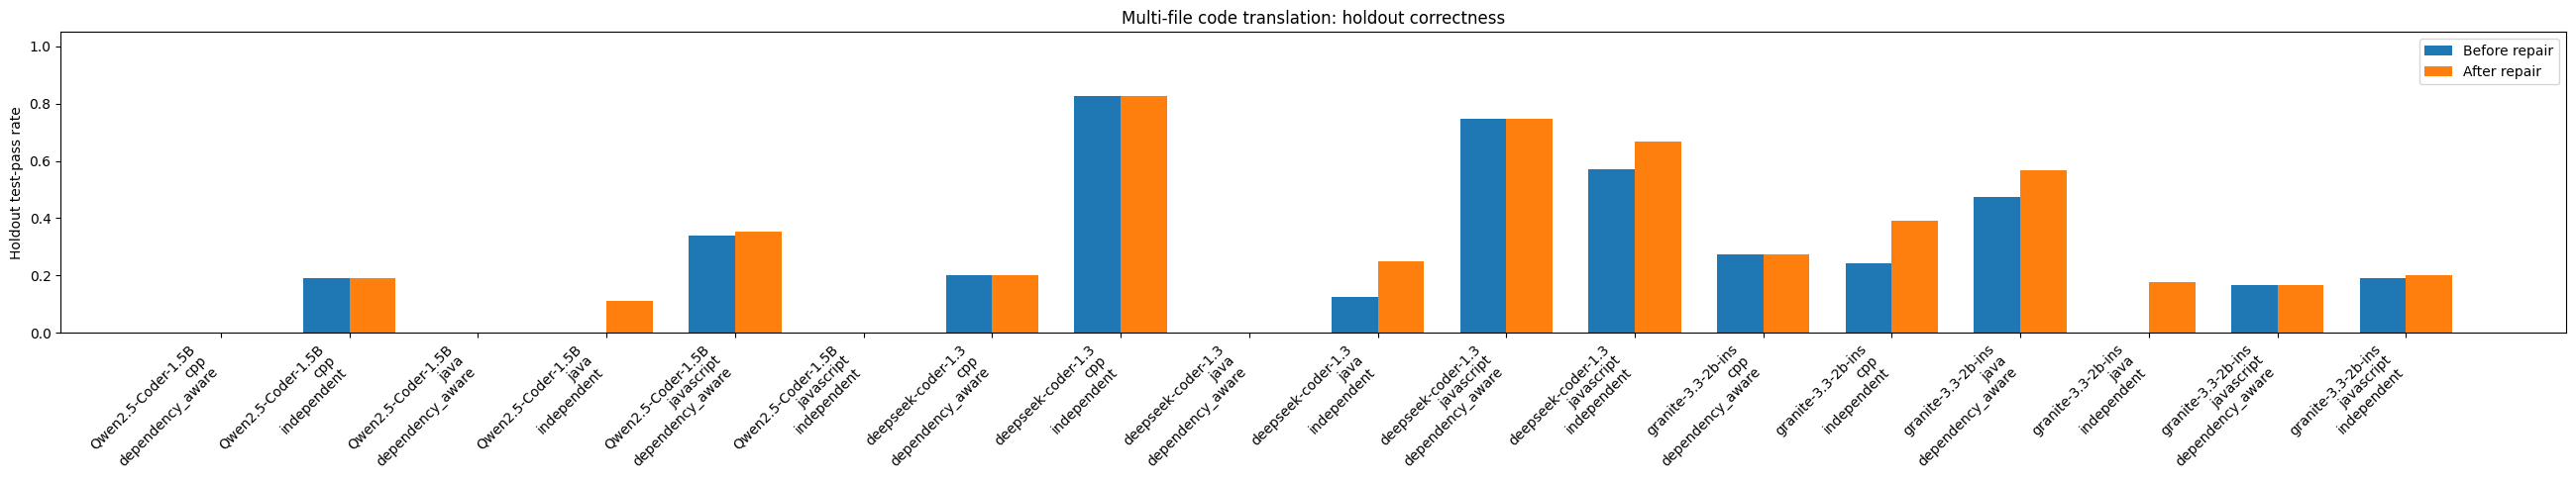

approach                                                                 dependency_aware  \
model                               project             target_language                     
Qwen/Qwen2.5-Coder-1.5B-Instruct    calendar_dates      cpp                             0   
                                                        java                            0   
                                                        javascript                     18   
                                    electricity_bill    cpp                             0   
                                                        java                            0   
...                                                                                   ...   
ibm-granite/granite-3.3-2b-instruct stock_replenishment java                            0   
                                                        javascript                     18   
                                    tax_brackets        cpp                             0   
                                                        java                           21   
                                                        javascript                      0   

approach                                                                 independent  \
model                               project             target_language                
Qwen/Qwen2.5-Coder-1.5B-Instruct    calendar_dates      cpp                        0   
                                                        java                       0   
                                                        javascript                 0   
                                    electricity_bill    cpp                       27   
                                                        java                       0   
...                                                                              ...   
ibm-granite/granite-3.3-2b-instruct stock_replenishment java                      12   
                                                        javascript                22   
                                    tax_brackets        cpp                        0   
                                                        java                       0   
                                                        javascript                 0   

approach                                                                 dependency_gain_in_passed_tests  
model                               project             target_language                                   
Qwen/Qwen2.5-Coder-1.5B-Instruct    calendar_dates      cpp                                            0  
                                                        java                                           0  
                                                        javascript                                    18  
                                    electricity_bill    cpp                                          -27  
                                                        java                                           0  
...                                                                                                  ...  
ibm-granite/granite-3.3-2b-instruct stock_replenishment java                                         -12  
                                                        javascript                                    -4  
                                    tax_brackets        cpp                                            0  
                                                        java                                          21  
                                                        javascript                                     0  

[72 rows x 3 columns]

Results ZIP: /content/MSCS811_multifile_translation_v2_full/experiment_results.zip


In [26]:
if not RESULTS_CSV.exists():
    raise RuntimeError('No completed experiment rows; inspect experiment_errors.jsonl')
df = pd.read_csv(RESULTS_CSV)
display(df[['model','project','target_language','approach',
            'initial_holdout_passed','final_holdout_passed','holdout_total',
            'repair_attempts','accepted_repairs','initial_error_category',
            'final_error_category','truncated_output_calls','generation_seconds']])

summary = (df.groupby(['model','target_language','approach'], as_index=False)
             .agg(runs=('project','count'),
                  initial_passed=('initial_holdout_passed','sum'),
                  final_passed=('final_holdout_passed','sum'),
                  total_tests=('holdout_total','sum'),
                  initial_projects_pass=('initial_holdout_project_success','sum'),
                  final_projects_pass=('final_holdout_project_success','sum'),
                  llm_calls=('llm_calls','sum'),
                  repair_attempts=('repair_attempts','sum'),
                  accepted_repairs=('accepted_repairs','sum'),
                  truncated_output_calls=('truncated_output_calls','sum'),
                  generation_seconds=('generation_seconds','sum'),
                  end_to_end_seconds=('end_to_end_seconds','sum')))
summary['initial_test_pass_rate'] = summary['initial_passed']/summary['total_tests']
summary['final_test_pass_rate'] = summary['final_passed']/summary['total_tests']
summary['initial_project_success_rate'] = summary['initial_projects_pass']/summary['runs']
summary['final_project_success_rate'] = summary['final_projects_pass']/summary['runs']
summary.to_csv(RESULT_ROOT/'aggregated_summary.csv',index=False)
display(summary)

# Summarize failure modes and preserve representative Java compiler messages.
error_counts=(df.groupby(['model','target_language','approach',
                          'initial_error_category'],as_index=False)
                .size().rename(columns={'size':'project_runs'}))
error_counts.to_csv(RESULT_ROOT/'initial_error_distribution.csv',index=False)
display(error_counts)
java_diagnostics=[]
for record in df[df['target_language']=='java'].itertuples():
    src=(RESULT_ROOT/'runs'/slug(record.model)/record.approach/'java'/
         record.project/'initial'/'validate_holdout'/'compile_stderr.txt')
    if src.exists() and src.read_text().strip():
        java_diagnostics.append({'model':record.model,'project':record.project,
            'approach':record.approach,'compiler_error':src.read_text()[:2500]})
if java_diagnostics:
    pd.DataFrame(java_diagnostics).to_csv(
        RESULT_ROOT/'java_compiler_diagnostics.csv',index=False)
    print('Saved Java compilation diagnostics:',len(java_diagnostics),'runs')
print('Rejected repair candidates remain in repair logs but are not retained as final code.')

# Number of initially failing projects rescued after repair (not test-case rescue rate).
failed_runs = df[df['initial_holdout_project_success']==0].copy()
repair_rate = (failed_runs.groupby(['model','target_language','approach'])
               ['final_holdout_project_success'].mean().rename('rescue_rate')
               .reset_index()) if len(failed_runs) else pd.DataFrame()
if len(repair_rate):
    display(repair_rate)
    repair_rate.to_csv(RESULT_ROOT/'repair_rescue_rate.csv',index=False)

if len(summary):
    labels = [f"{row.model.split('/')[-1][:18]}\n{row.target_language}\n{row.approach}"
              for row in summary.itertuples()]
    positions = list(range(len(summary)))
    fig,ax = plt.subplots(figsize=(max(11,len(summary)*1.45),5))
    ax.bar([i-.18 for i in positions],summary['initial_test_pass_rate'],width=.36,label='Before repair')
    ax.bar([i+.18 for i in positions],summary['final_test_pass_rate'],width=.36,label='After repair')
    ax.set_xticks(positions,labels,rotation=45,ha='right')
    ax.set_ylim(0,1.05)
    ax.set_ylabel('Holdout test-pass rate')
    ax.set_title('Multi-file code translation: holdout correctness')
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULT_ROOT/'holdout_accuracy.png',dpi=180)
    plt.show()

# Paired approach delta: + means dependency-aware outperforms independent.
paired = df.pivot_table(index=['model','project','target_language'],
                        columns='approach',values='final_holdout_passed',aggfunc='first')
if all(x in paired.columns for x in APPROACHES):
    paired = paired.dropna(subset=APPROACHES)
    paired['dependency_gain_in_passed_tests'] = paired['dependency_aware']-paired['independent']
    paired.to_csv(RESULT_ROOT/'paired_dependency_comparison.csv')
    display(paired)

# Download results ZIP from Colab after execution (generated code, logs, charts, CSVs).
archive = shutil.make_archive(str(ROOT/'experiment_results'), 'zip', RESULT_ROOT)
print('Results ZIP:',archive)
try:
    from google.colab import files
    # Uncomment after the experiment to download automatically:
    # files.download(archive)
except ImportError:
    pass

## Methodology and limitations for the MSCS811 report
- Compare models across **identical** source projects and test inputs.
- This is a small synthetic integer-function benchmark, **not** representative of arbitrary repositories.
- Baseline vs dependency-aware compares explicit **dependency context**, not translation order.
- All three checkpoints use instruction prompts, but differ in training, architectures and capacity.
- Repair feedback uses only development cases. Holdout cases are never placed in prompts.
- Repair candidates are accepted only if the feedback suite improves (holdout can still regress).
- Java, JavaScript, C++ validator self-tests pass before LLMs run. A model's Java failure
  after that is a generation/integration failure, not evidence that Java tests are broken.
- Python AST extraction handles straightforward acyclic local imports only; no dynamic imports,
  namespace packages, dependency version management, or cross-repository imports.
- Generation is not deterministic across every hardware/software stack even with greedy decoding.
- v2 stores pilot/full results separately; previous experimental results are not mixed.
- Diagnostic logs contain development feedback and generated code; never upload private repositories.
- end_to_end_seconds includes local compilation/testing (generation_seconds does not).
- The source files and their tests are created by this notebook, not obtained from real projects.
- Colab subprocess timeouts are NOT a security boundary. Run generated code only in isolation.

**Official model documentation:**
- https://huggingface.co/Qwen/Qwen2.5-Coder-1.5B-Instruct
- https://huggingface.co/deepseek-ai/deepseek-coder-1.3b-instruct
- https://huggingface.co/ibm-granite/granite-3.3-2b-instruct
- https://huggingface.co/docs/transformers/main/chat_templating